# Pt薄膜：同一论文内部的演示性回归与留一法验证

本Notebook落实已提交ТЗ中的Pt回归、MAE、R²、相关性热图和实测—预测图。8条Pt记录均来自同一篇论文。此模型仅用于演示Python建模流程，样本量不足以证明一般化预测能力。

来源：Kljajo等，*Coatings* 2026，DOI `10.3390/coatings16010008`，Table 1。

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import LeaveOneOut, LeaveOneGroupOut

plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 180, 'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})

def locate_data_file():
    filename = 'pvd_experiments_verified_v3.csv'
    start = Path.cwd().resolve()
    for root in [start, *start.parents]:
        for path in [root / filename, root / 'outputs' / 'pvd_public_data_v3' / filename, root / '项目名' / 'outputs' / 'pvd_public_data_v3' / filename]:
            if path.is_file():
                return path
    raise FileNotFoundError(f'未找到 {filename}')

data_path = locate_data_file()
output_dir = data_path.parent / 'pt_model'
output_dir.mkdir(parents=True, exist_ok=True)
print('数据文件：', data_path)
print('模型输出：', output_dir)

数据文件： /mnt/d/学业/项目名/outputs/pvd_public_data_v3/pvd_experiments_verified_v3.csv
模型输出： /mnt/d/学业/项目名/outputs/pvd_public_data_v3/pt_model


## 1. 选择单一来源的Pt样本

Pt论文报告的是放电电流，不是功率。模型只使用该论文中8条可配对的沉积时间、工作压力、电流和膜厚。

In [2]:
all_data = pd.read_csv(data_path)
pt = all_data.loc[(all_data.target_material == 'Pt') & (all_data.source_id == 'S01')].copy().sort_values('experiment_id').reset_index(drop=True)
required = ['deposition_time_min', 'pressure_Pa', 'discharge_current_mA', 'film_thickness_nm']
assert len(pt) == 8 and pt[required].notna().all().all()
assert pt.verification_status.eq('verified').all() and pt.thickness_status.eq('reported_measured').all()
assert pt.source_doi.eq('10.3390/coatings16010008').all()
pt['calculated_rate_nm_min'] = pt.film_thickness_nm / pt.deposition_time_min
display(pt[['experiment_id', 'deposition_time_min', 'pressure_Pa', 'discharge_current_mA', 'film_thickness_nm', 'calculated_rate_nm_min']])

,experiment_id,deposition_time_min,pressure_Pa,discharge_current_mA,film_thickness_nm,calculated_rate_nm_min
0,PT-01,2,0.5,50.0,51.5,25.750000
1,PT-02,12,0.5,50.0,302.0,25.166667
2,PT-03,2,1.5,50.0,41.5,20.750000
3,PT-04,12,1.5,50.0,215.0,17.916667
4,PT-05,2,0.5,70.0,72.1,36.050000
5,PT-06,12,0.5,70.0,428.4,35.700000
6,PT-07,2,1.5,70.0,62.3,31.150000
7,PT-08,12,1.5,70.0,374.3,31.191667


## 2. Pt组数值字段的相关性热图

Pearson相关系数只描述这8条记录的线性共同变化。样本量很小，不能将相关系数当作因果结论。`calculated_rate_nm_min`由膜厚除以时间算出，因此它与膜厚不是独立观测。

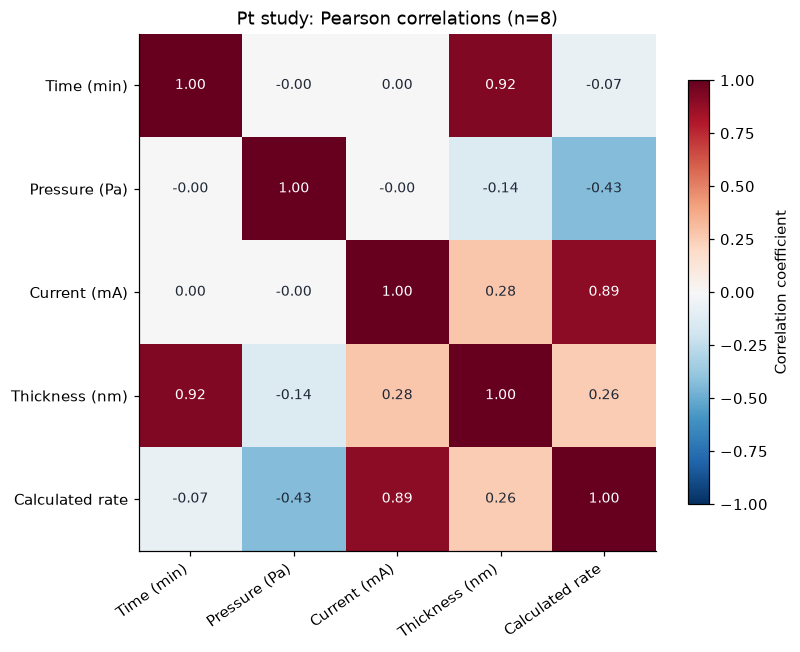

In [3]:
corr_columns = ['deposition_time_min', 'pressure_Pa', 'discharge_current_mA', 'film_thickness_nm', 'calculated_rate_nm_min']
corr_labels = ['Time (min)', 'Pressure (Pa)', 'Current (mA)', 'Thickness (nm)', 'Calculated rate']
corr = pt[corr_columns].corr(method='pearson')
corr.to_csv(output_dir / 'pt_correlation_matrix.csv', encoding='utf-8-sig')
fig, ax = plt.subplots(figsize=(7.4, 6.0))
im = ax.imshow(corr.values, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_labels)), corr_labels, rotation=35, ha='right')
ax.set_yticks(range(len(corr_labels)), corr_labels)
for row in range(len(corr_labels)):
    for col in range(len(corr_labels)):
        value = corr.iat[row, col]
        ax.text(col, row, f'{value:.2f}', ha='center', va='center', color='white' if abs(value) > 0.65 else '#1f2937', fontsize=9)
ax.set_title('Pt study: Pearson correlations (n=8)')
fig.colorbar(im, ax=ax, label='Correlation coefficient', shrink=0.82)
fig.tight_layout()
fig.savefig(output_dir / '01_pt_correlation_heatmap.png', bbox_inches='tight')
plt.show()

## 3. 回归模型与留一法

对每条测试记录，先用其余7条记录训练线性回归，预测平均沉积速率，再乘以该测试记录的沉积时间得到膜厚预测。模型输入为压力和放电电流。沉积时间仅用于把预测速率换算为膜厚。每折的训练集不含测试记录。

比较基线：使用其余7条记录的平均沉积速率乘以测试记录的沉积时间。这样模型和基线都遵守相同的留一法。

In [4]:
X = pt[['pressure_Pa', 'discharge_current_mA']].to_numpy(dtype=float)
time_min = pt.deposition_time_min.to_numpy(dtype=float)
y_thickness = pt.film_thickness_nm.to_numpy(dtype=float)
y_rate = y_thickness / time_min
predicted_thickness = np.empty(len(pt), dtype=float)
baseline_thickness = np.empty(len(pt), dtype=float)

for train_index, test_index in LeaveOneOut().split(X):
    model = LinearRegression().fit(X[train_index], y_rate[train_index])
    predicted_rate = model.predict(X[test_index])
    predicted_thickness[test_index] = predicted_rate * time_min[test_index]
    baseline_thickness[test_index] = y_rate[train_index].mean() * time_min[test_index]

predictions = pt[['experiment_id', 'source_id', 'deposition_time_min', 'pressure_Pa', 'discharge_current_mA', 'film_thickness_nm']].copy()
predictions = predictions.rename(columns={'film_thickness_nm': 'measured_thickness_nm'})
predictions['predicted_thickness_nm'] = predicted_thickness
predictions['residual_nm'] = y_thickness - predicted_thickness
predictions['absolute_error_nm'] = np.abs(predictions.residual_nm)
predictions['baseline_predicted_nm'] = baseline_thickness
predictions['baseline_absolute_error_nm'] = np.abs(y_thickness - baseline_thickness)
predictions.to_csv(output_dir / 'pt_loo_predictions.csv', index=False, encoding='utf-8-sig')
display(predictions.round(2))

,experiment_id,source_id,deposition_time_min,pressure_Pa,discharge_current_mA,measured_thickness_nm,predicted_thickness_nm,residual_nm,absolute_error_nm,baseline_predicted_nm,baseline_absolute_error_nm
0,PT-01,S01,2,0.5,50.0,51.5,49.43,2.07,2.07,56.55,5.05
1,PT-02,S01,12,0.5,50.0,302.0,300.78,1.22,1.22,340.30,38.30
2,PT-03,S01,2,1.5,50.0,41.5,38.10,3.40,3.40,57.98,16.48
3,PT-04,S01,12,1.5,50.0,215.0,249.02,-34.02,34.02,352.73,137.73
4,PT-05,S01,2,0.5,70.0,72.1,72.68,-0.58,0.58,53.61,18.49
5,PT-06,S01,12,0.5,70.0,428.4,438.58,-10.18,10.18,322.24,106.16
6,PT-07,S01,2,1.5,70.0,62.3,61.23,1.07,1.07,55.01,7.29
7,PT-08,S01,12,1.5,70.0,374.3,367.08,7.22,7.22,329.97,44.33


## 4. 评价指标

MAE的单位是nm，越低越好。R²在此处按全部8个留一法预测计算；可能为负，表示预测比常数均值还差。这里不把训练集拟合分数当作验证分数。

In [5]:
metrics = pd.DataFrame([
    {'method': 'Linear regression on calculated rate', 'validation': 'leave-one-out', 'records': len(pt), 'MAE_nm': mean_absolute_error(y_thickness, predicted_thickness), 'R2': r2_score(y_thickness, predicted_thickness), 'negative_predictions': int((predicted_thickness < 0).sum())},
    {'method': 'Training-mean calculated rate baseline', 'validation': 'leave-one-out', 'records': len(pt), 'MAE_nm': mean_absolute_error(y_thickness, baseline_thickness), 'R2': r2_score(y_thickness, baseline_thickness), 'negative_predictions': int((baseline_thickness < 0).sum())},
])
metrics.to_csv(output_dir / 'pt_loo_metrics.csv', index=False, encoding='utf-8-sig')
display(metrics.round(3))
print('模型最大的单条绝对误差（nm）：', round(float(predictions.absolute_error_nm.max()), 2))

,method,validation,records,MAE_nm,R2,negative_predictions
0,Linear regression on calculated rate,leave-one-out,8,7.469,0.992,0
1,Training-mean calculated rate baseline,leave-one-out,8,46.729,0.804,0


模型最大的单条绝对误差（nm）： 34.02


## 补充验证：整组留出一种压力—电流组合

Pt数据有4种压力—电流组合，每种各有2分钟和12分钟记录。留一法的训练集中仍包含同一组合的另一条记录。这里把同一组合的两条记录一起留出，观察模型对未见过的组合的预测表现。该结果用于评价适用范围，不替代ТЗ指定的留一法指标。

In [6]:
condition_group = pt.pressure_Pa.astype(str) + ' Pa; ' + pt.discharge_current_mA.astype(int).astype(str) + ' mA'
group_predicted = np.empty(len(pt), dtype=float)
for train_index, test_index in LeaveOneGroupOut().split(X, groups=condition_group):
    model = LinearRegression().fit(X[train_index], y_rate[train_index])
    group_predicted[test_index] = model.predict(X[test_index]) * time_min[test_index]
group_check = pd.DataFrame({'experiment_id': pt.experiment_id, 'held_out_condition': condition_group, 'measured_thickness_nm': y_thickness, 'predicted_thickness_nm': group_predicted, 'residual_nm': y_thickness - group_predicted})
group_check.to_csv(output_dir / 'pt_leave_condition_out_predictions.csv', index=False, encoding='utf-8-sig')
print('整组留出 MAE (nm):', round(mean_absolute_error(y_thickness, group_predicted), 3))
print('整组留出 R²:', round(r2_score(y_thickness, group_predicted), 3))
display(group_check.round(2))

整组留出 MAE (nm): 11.597
整组留出 R²: 0.988


,experiment_id,held_out_condition,measured_thickness_nm,predicted_thickness_nm,residual_nm
0,PT-01,0.5 Pa; 50 mA,51.5,48.08,3.43
1,PT-02,0.5 Pa; 50 mA,302.0,288.45,13.55
2,PT-03,1.5 Pa; 50 mA,41.5,41.51,-0.01
3,PT-04,1.5 Pa; 50 mA,215.0,249.05,-34.05
4,PT-05,0.5 Pa; 70 mA,72.1,74.59,-2.49
5,PT-06,0.5 Pa; 70 mA,428.4,447.55,-19.15
6,PT-07,1.5 Pa; 70 mA,62.3,59.50,2.80
7,PT-08,1.5 Pa; 70 mA,374.3,357.00,17.30


## 5. 实测—预测膜厚与残差

虚线表示预测值与实测值完全相等。每个标签对应一条被留出的实验记录，便于定位偏差来源。

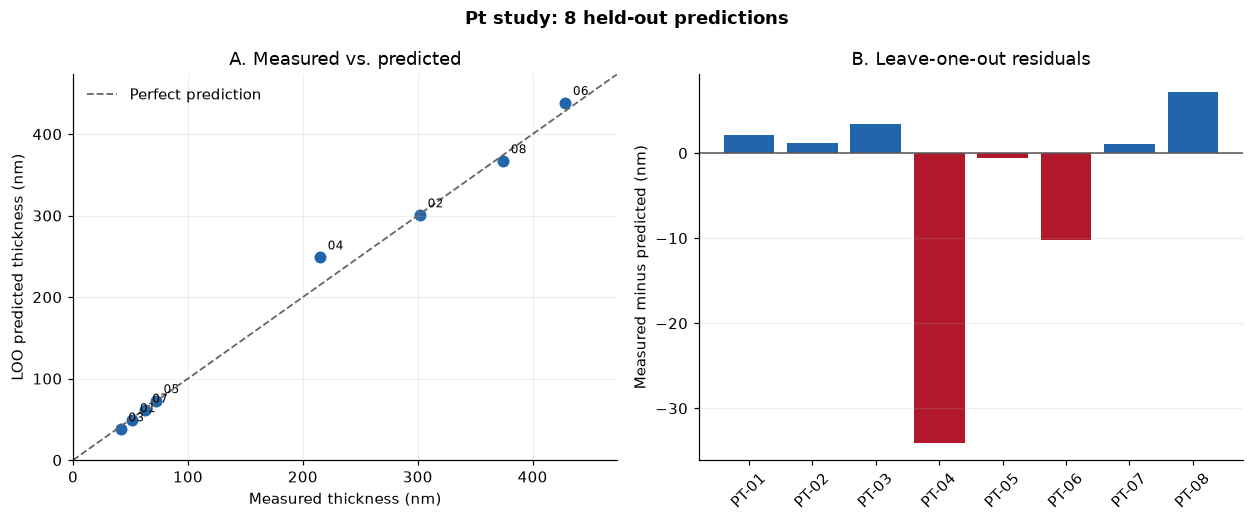

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.8))
ax1.scatter(y_thickness, predicted_thickness, s=75, color='#2166ac', edgecolor='white', linewidth=0.8)
limits = [0, max(y_thickness.max(), predicted_thickness.max()) * 1.08]
ax1.plot(limits, limits, '--', color='#666666', linewidth=1.2, label='Perfect prediction')
for measured, predicted, label in zip(y_thickness, predicted_thickness, pt.experiment_id):
    ax1.annotate(label.replace('PT-', ''), (measured, predicted), xytext=(5, 5), textcoords='offset points', fontsize=8)
ax1.set_xlim(limits); ax1.set_ylim(limits)
ax1.set_xlabel('Measured thickness (nm)')
ax1.set_ylabel('LOO predicted thickness (nm)')
ax1.set_title('A. Measured vs. predicted')
ax1.grid(alpha=0.2); ax1.legend(frameon=False)

bar_colors = ['#b2182b' if value < 0 else '#2166ac' for value in predictions.residual_nm]
ax2.bar(predictions.experiment_id, predictions.residual_nm, color=bar_colors)
ax2.axhline(0, color='#555555', linewidth=1)
ax2.tick_params(axis='x', rotation=45)
ax2.set_ylabel('Measured minus predicted (nm)')
ax2.set_title('B. Leave-one-out residuals')
ax2.grid(axis='y', alpha=0.2)
fig.suptitle('Pt study: 8 held-out predictions', fontsize=12, fontweight='bold')
fig.tight_layout()
fig.savefig(output_dir / '02_pt_measured_vs_predicted.png', bbox_inches='tight')
plt.show()

## 6. Pt论文内部的膜厚—参数图

这组图补充ТЗ要求的膜厚与时间、压力及控制参数（电流）的关系。每个点代表一条实际实验记录；这些投影图不能单独隔离其他变量的影响。

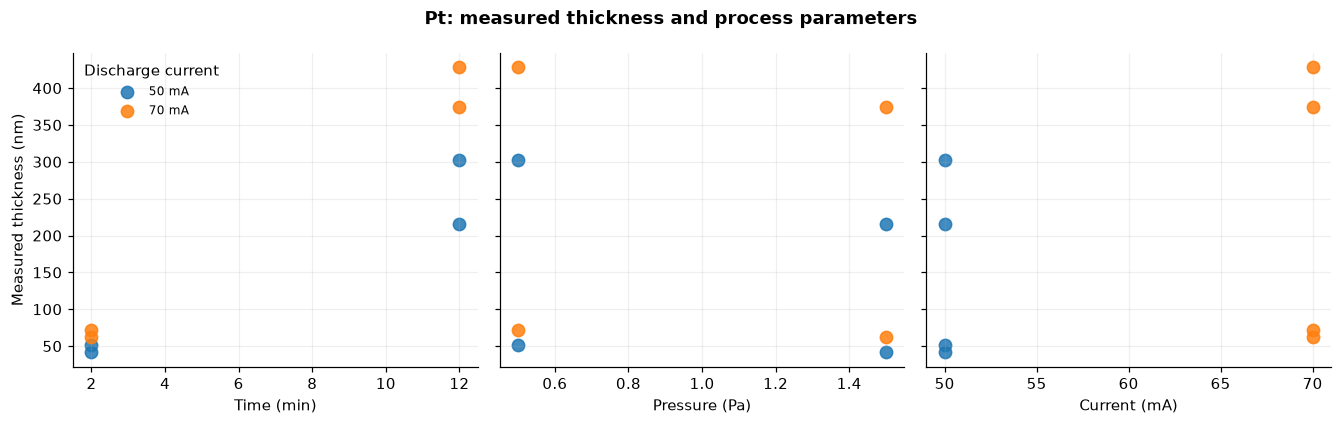

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(12.3, 3.9), sharey=True)
features = [('deposition_time_min', 'Time (min)'), ('pressure_Pa', 'Pressure (Pa)'), ('discharge_current_mA', 'Current (mA)')]
for ax, (column, label) in zip(axes, features):
    for current, group in pt.groupby('discharge_current_mA'):
        ax.scatter(group[column], group.film_thickness_nm, s=65, alpha=0.85, label=f'{current:g} mA')
    ax.set_xlabel(label)
    ax.grid(alpha=0.2)
axes[0].set_ylabel('Measured thickness (nm)')
axes[0].legend(title='Discharge current', frameon=False, fontsize=8)
fig.suptitle('Pt: measured thickness and process parameters', fontsize=12, fontweight='bold')
fig.tight_layout()
fig.savefig(output_dir / '03_pt_thickness_parameter_views.png', bbox_inches='tight')
plt.show()

## 结果解释与局限

1. MAE和R²来自8次留一法预测，逐条预测及残差保存在CSV中。模型与基线使用完全相同的折分。
2. 留一法训练样本每折只有7条，而且训练集中可能存在同一压力—电流组合的另一条记录。整组留出组合的补充结果更接近对未见组合的检验。
3. 线性模型只在Pt单篇论文范围内建立。跨材料、跨设备预测不在本模型范围内。
4. 平均沉积速率是计算量；Pt论文另行报告的速率没有被直接用作模型目标，防止与输入膜厚形成信息泄漏。